## **Shallow water equations**

\begin{cases}
\dfrac{\partial \mathbf{u}(\mathbf{x},t)}{\partial t} = -\mathbf{u}(\mathbf{x},t) \cdot \nabla \mathbf{u}(\mathbf{x},t) - g \nabla h(\mathbf{x},t) - \nu \Delta^2 \mathbf{u}(\mathbf{x},t) - 2f \times u(\mathbf{x},t) \qquad &\mathrm{in } \ \Omega \times (0,T)
\\[7pt]
\dfrac{\partial h(\mathbf{x},t)}{\partial t} = -H \nabla \cdot \mathbf{u}(\mathbf{x},t) - \nabla \cdot (h(\mathbf{x},t) \mathbf{u}(\mathbf{x},t)) -\nu \Delta^2 h(\mathbf{x},t) + F(\mathbf{x},t) \qquad &\mathrm{in } \ \Omega \times (0,T)
\end{cases}


where $\Omega$ is the domain, $T > 0$ is the final time, $\mathbf{u}: \Omega \times [0,T] \to \mathbb{R}^2$ is the unknown velocity field, $h: \Omega \times [0,T] \to \mathbb{R}$ is the unknown height deviation of the horizontal pressure surface from its mean height, $F: \Omega \times [0,T] \to \mathbb{R}$ is a source term forcing annual and daily periodicity, $g$ is the gravity acceleration, $H$ is the mean height of the horizontal pressure surface, $f$ is the Coriolis coefficient and $\nu$ is the viscosity parameter

In [34]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [35]:

#IMPORT LIBRARIES

import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys
import cmcrameri.cm as cmc
import pandas as pd

from __future__ import print_function
from IPython.display import clear_output as clc

from the_well.data import WellDataset
from the_well.utils.download import well_download
from sklearn.utils.extmath import randomized_svd
from sklearn.preprocessing import MinMaxScaler

# Add parent directory to path to access src module
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent.parent))
print("Current working directory:", Path.cwd())
print("Parent directory added to path:", Path.cwd().parent.parent)

# my packages
from src.processdata import trajectory, Padding, PaddingGRUD, TimeSeriesDataset, MaskedTimeSeriesDataset, PaddingMask
from src.tshred.TSHRED import TSHRED, fit
from src.shred.SHRED_GRUD import SHRED_GRUD, fit as fit_grud
from src.utils import mre, num2p


Current working directory: /home/matteo/Documents/Masked-SHRED/Notebooks/SWE
Parent directory added to path: /home/matteo/Documents/Masked-SHRED


## Data Load

In [36]:
# ONLY RUN THIS ONCE TO DOWNLOAD THE DATASET
# well_download(base_path="", dataset="planetswe", split="train", first_only=True)

In [ ]:
# LOAD THE DATASET

data_folder = "datasets"
dataset = WellDataset(
    well_base_path = data_folder,
    well_dataset_name = "planetswe",
    well_split_name = "train",
    n_steps_input = 1008,
    n_steps_output = 0,
    use_normalization = False,
)
#I've downloaded 0 and 1, you can change this to load the other ones
dataset = dataset[0] 

# BUILD SNAPSHOTS MATRICES

theta = dataset["space_grid"][:,:,0]    # theta: colatitude angle (radians) at each grid point, shape (Lx, Ly)
phi = dataset["space_grid"][:,:,1]      # phi: longitude angle (radians) at each grid point, shape (Lx, Ly)

print("theta shape:\t", theta.shape)
print("phi shape:\t", phi.shape)

ntimes, Lx, Ly, _ = dataset['input_fields'].shape   # ntimes: number of time steps, Lx: number of grid points in x (colatitude), Ly: number of grid points in y (longitude)
nheight = nvelocity = Lx * Ly                       # total number of spatial grid points (flattened)

print("ntimes:\t\t", ntimes)    
print("Lx:\t\t", Lx)            
print("Ly:\t\t", Ly)            
print("nheight:\t", nheight)
print("nvelocity:\t", nvelocity)

H = dataset["input_fields"][:,:,:,0].reshape(ntimes, nheight)           # H: snapshot matrix of height deviation h(x,t), shape (ntimes, nheight)
Utheta = dataset["input_fields"][:,:,:,1].reshape(ntimes, nvelocity)    # Utheta: snapshot matrix of velocity component along colatitude, shape (ntimes, nvelocity)
Uphi = dataset["input_fields"][:,:,:,2].reshape(ntimes, nvelocity)      # Uphi: snapshot matrix of velocity component along longitude, shape (ntimes, nvelocity)

print("H shape:\t", H.shape)
print("Utheta shape:\t", Utheta.shape)
print("Uphi shape:\t", Uphi.shape)

# DELETE DATASET TO FREE UP MEMORY

del dataset

In [ ]:
# Define a function to plot the state of the system at a given time step
def plot_state(
    u, cmap = "RdBu_r", 
    colorbar = False, shrink = 1.0, extent = None, vmin = None, vmax = None
):
    fig = plt.imshow(u.reshape(Lx, Ly), extent = extent, cmap = cmap, vmin = vmin, vmax = vmax, origin = 'lower')
    if colorbar:
        plt.colorbar(fig, shrink = shrink)

# Define a function to plot the height field using a specific colormap
plot_height = lambda u: plot_state(u, cmap = "gist_earth")
# Define a function to plot the velocity field using a specific colormap
plot_velocity = lambda u: plot_state(u, cmap = "RdBu_r")

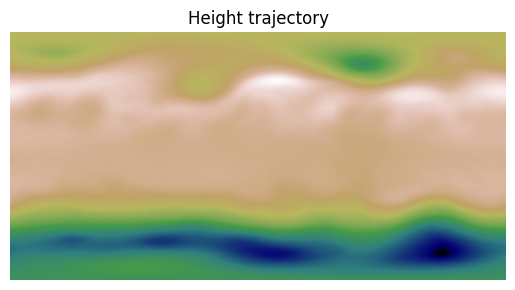

In [ ]:
#Plot the trajectory of the height field for the first 50 time steps
whichtimes = np.arange(0,50)
trajectory(H[whichtimes], plot_height, title = "Height trajectory", fontsize = 12)

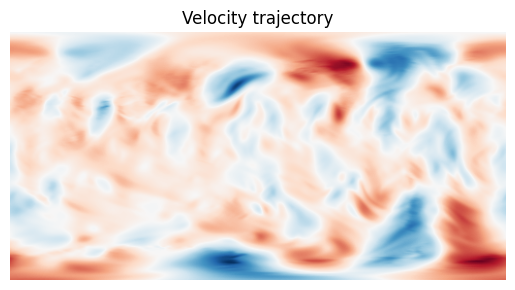

In [ ]:
#Plot the trajectory of the velocity field for the first 50 time steps
whichtimes = np.arange(0,50)
trajectory(Utheta[whichtimes], plot_velocity, title = "Velocity trajectory", fontsize = 12)

## SENSOR DATA - fixed sensors 

In [43]:
# EXTRACT SENSORS DATA 

# We randomly select 4 sensors on the grid and extract their time series data from the height field H. 
nsensors = 4
sensors_coordinates = np.vstack((np.random.choice(Lx, size = nsensors, replace = True), np.random.choice(Ly, size = nsensors, replace = True))).T

sensors_data = H.reshape(ntimes, Lx, Ly)[:,sensors_coordinates[:,0], sensors_coordinates[:,1]]
print("Sensors coordinates:\n", sensors_coordinates)
print("Sensors data shape:\t", sensors_data.shape)

Sensors coordinates:
 [[144 465]
 [217 217]
 [ 75 386]
 [220 369]]
Sensors data shape:	 torch.Size([1008, 4])


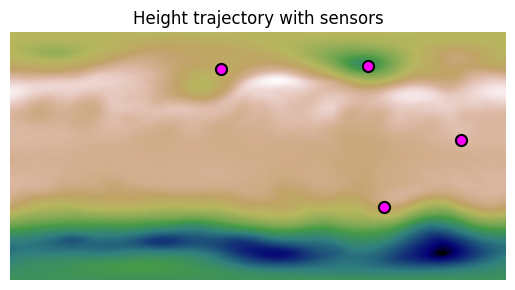

In [44]:
# TRAJECTORY WITH SENSORS (PLOT) 

def trajectory_with_sensors(ut, sensors_coordinates, title = None):
    
    for i in range(ut.shape[0]):
        plot_state(ut[i], cmap = "gist_earth")

        # Plot sensors locations on top of the height field
        for k in np.arange(nsensors):
            plt.plot(sensors_coordinates[k,1], sensors_coordinates[k,0], 'o', mfc = 'magenta', mec = 'black', ms = 8, mew = 1.5)
        
        plt.title(title)
        plt.axis('off')
        display(plt.gcf())
        plt.close()
        clc(wait=True)

whichtimes = np.arange(0, 50)
trajectory_with_sensors(H[whichtimes], sensors_coordinates, title = "Height trajectory with sensors")

## TRAIN VAL TEST split

In [45]:
np.random.seed(0)

# dimensions
ntrain = round(0.8 * ntimes)

# split indices (random shuffle)
idx_train = np.random.choice(ntimes, size = ntrain, replace = False)
mask = np.ones(ntimes)
mask[idx_train] = 0
idx_valid_test = np.arange(0, ntimes)[np.where(mask != 0)[0]]
idx_valid = idx_valid_test[::2]
idx_test  = idx_valid_test[1::2]

nvalid = len(idx_valid)
ntest  = len(idx_test)

# split
H_train = H[idx_train]
sensor_train, sensor_valid, sensor_test = sensors_data[idx_train], sensors_data[idx_valid], sensors_data[idx_test]

print("Number of training samples:\t", ntrain)
print("Number of validation samples:\t", nvalid)
print("Number of test samples:\t\t", ntest)

print("\nIN:")
print("sensor_train shape:\t", sensor_train.shape)

print("\nOUT:")
print("H_train shape:\t\t", H_train.shape)


Number of training samples:	 806
Number of validation samples:	 101
Number of test samples:		 101

IN:
sensor_train shape:	 torch.Size([806, 4])

OUT:
H_train shape:		 torch.Size([806, 131072])


## POD Reduction

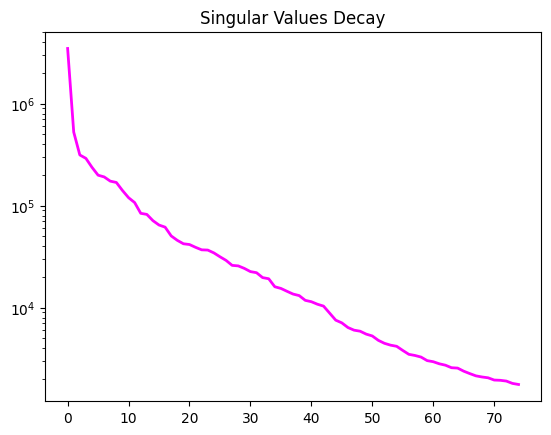

torch.Size([1008, 131072])  -->  torch.Size([1008, 75])


In [46]:
POD_modes = 75 # Number of POD modes

# Perform randomized SVD on the training data to compute the POD modes
_, S_POD, V_POD = randomized_svd(H_train.numpy(), n_components = POD_modes)

# Plot the decay of the singular values to visualize how much energy is captured by the POD modes
plt.semilogy(S_POD, color = 'magenta', linewidth = 2)
plt.title("Singular Values Decay")
plt.show()

# VH_POD: (POD_modes, nheight) - the POD basis
VH_POD = V_POD   # already POD_modes rows, no slicing needed

# Project all time steps onto the POD basis at once
H_POD = H @ VH_POD.T   # (ntimes, POD_modes)

# Print the shapes to verify dimensionality reduction
print(H.shape, " --> ", H_POD.shape)


In [47]:
# Scale the sensor inputs to the range [0, 1] using MinMaxScaler (fit on train only)
scaler_sensors = MinMaxScaler()
scaler_sensors = scaler_sensors.fit(sensor_train)

# Transform sensor data and convert to tensors
sensor_train = torch.from_numpy(scaler_sensors.transform(sensor_train))
sensor_valid = torch.from_numpy(scaler_sensors.transform(sensor_valid))
sensor_test  = torch.from_numpy(scaler_sensors.transform(sensor_test))

# Scale the POD coefficients to the range [0, 1] using MinMaxScaler (fit on train only)
scalerH_POD = MinMaxScaler()
scalerH_POD = scalerH_POD.fit(H_POD[idx_train])

# Transform all time steps and convert to a single PyTorch tensor
H_POD = torch.from_numpy(scalerH_POD.transform(H_POD).reshape(ntimes, POD_modes))

# Split into train / validation / test by index
H_POD_train = H_POD[idx_train]
H_POD_valid = H_POD[idx_valid]
H_POD_test  = H_POD[idx_test]

# Print shapes to verify
print("H_POD_train ", H_POD_train.shape)
print("H_POD_valid ", H_POD_valid.shape)
print("H_POD_test  ", H_POD_test.shape)


H_POD_train  torch.Size([806, 75])
H_POD_valid  torch.Size([101, 75])
H_POD_test   torch.Size([101, 75])


## Benchmark all sensors

In [48]:
# BUILD TRAIN, VALIDATION AND TEST DATASETS WITH PADDING

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

lag = 100

train_data_in = Padding(sensor_train.unsqueeze(0), lag).to(device)
valid_data_in = Padding(sensor_valid.unsqueeze(0), lag).to(device)
test_data_in = Padding(sensor_test.unsqueeze(0), lag).to(device)

train_data_out = Padding(H_POD_train.unsqueeze(0), 1).squeeze(1).to(device)
valid_data_out = Padding(H_POD_valid.unsqueeze(0), 1).squeeze(1).to(device)
test_data_out = Padding(H_POD_test.unsqueeze(0), 1).squeeze(1).to(device)

train_dataset = TimeSeriesDataset(train_data_in, train_data_out)
valid_dataset = TimeSeriesDataset(valid_data_in, valid_data_out)
test_dataset = TimeSeriesDataset(test_data_in, test_data_out)

print(f"Train dataset shape: \n{train_data_in.shape} -> {train_data_out.shape}")
print(f"Validation dataset shape: \n{valid_data_in.shape} -> {valid_data_out.shape}")
print(f"Test dataset shape: \n{test_data_in.shape} -> {test_data_out.shape}")


Using device: cpu
Train dataset shape: 
torch.Size([806, 100, 4]) -> torch.Size([806, 75])
Validation dataset shape: 
torch.Size([101, 100, 4]) -> torch.Size([101, 75])
Test dataset shape: 
torch.Size([101, 100, 4]) -> torch.Size([101, 75])


In [49]:
model_args = dict(
    # Encoder
    encoder         = "vanilla_transformer",
    encoder_depth   = 1,
    d_model         = nsensors,   # input feature dim (one value per sensor)
    n_heads         = 4,
    dim_feedforward = 64,
    hidden_size     = 32,         # must be divisible by n_heads (32 / 4 = 8 ✓)
    input_length    = lag,

    # Decoder
    decoder         = "cnn",
    decoder_depth   = 2,
    output_size     = POD_modes,   # only H POD coefficients

    # Shared
    dropout         = 0.0,
    device          = device,
)
tshred = TSHRED(args=model_args)

In [50]:
train_errors, valid_errors = fit(
    tshred, train_dataset, valid_dataset, 
    batch_size = 64, epochs = 1000, lr = 1e-2, verbose = True, patience = 500, scheduler_patience=100
)


Training: 100%|██████████| 1000/1000 [02:18<00:00,  7.22it/s, Train Error=23.546%, Val Error=25.519%, Patience=217, Best Val Error=25.434%, LR=6.25e-04]

Training Complete (1000 epochs)


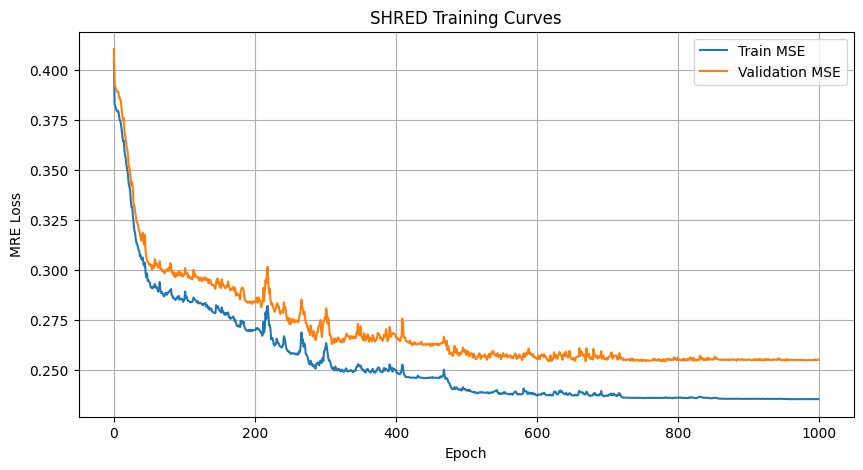

In [51]:
# PLOT TRAINING CURVES

plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MRE Loss')
plt.title('SHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

In [52]:
# TSHRED PREDICTIONS
tshred.freeze()

train_data_out_hat = tshred(train_data_in).cpu()
valid_data_out_hat = tshred(valid_data_in).cpu()
test_data_out_hat  = tshred(test_data_in).cpu()

# Inverse-transform POD coefficients back to the full spatial field
VH = torch.from_numpy(VH_POD).float()   # (POD_modes, nheight)

H_hat_train = torch.from_numpy(scalerH_POD.inverse_transform(train_data_out_hat.detach().numpy())).float() @ VH
H_hat_valid = torch.from_numpy(scalerH_POD.inverse_transform(valid_data_out_hat.detach().numpy())).float() @ VH
H_hat_test  = torch.from_numpy(scalerH_POD.inverse_transform(test_data_out_hat.detach().numpy())).float()  @ VH

ERRORS = []
ERRORS.append({
    "model": "TSHRED",
    "train_mre": num2p(mre(H[idx_train], H_hat_train)),
    "valid_mre": num2p(mre(H[idx_valid], H_hat_valid)),
    "test_mre": num2p(mre(H[idx_test],  H_hat_test)),
})
dataframe_errors = pd.DataFrame(ERRORS)
print(dataframe_errors)

    model train_mre valid_mre test_mre
0  TSHRED    3.879%    4.525%   4.662%


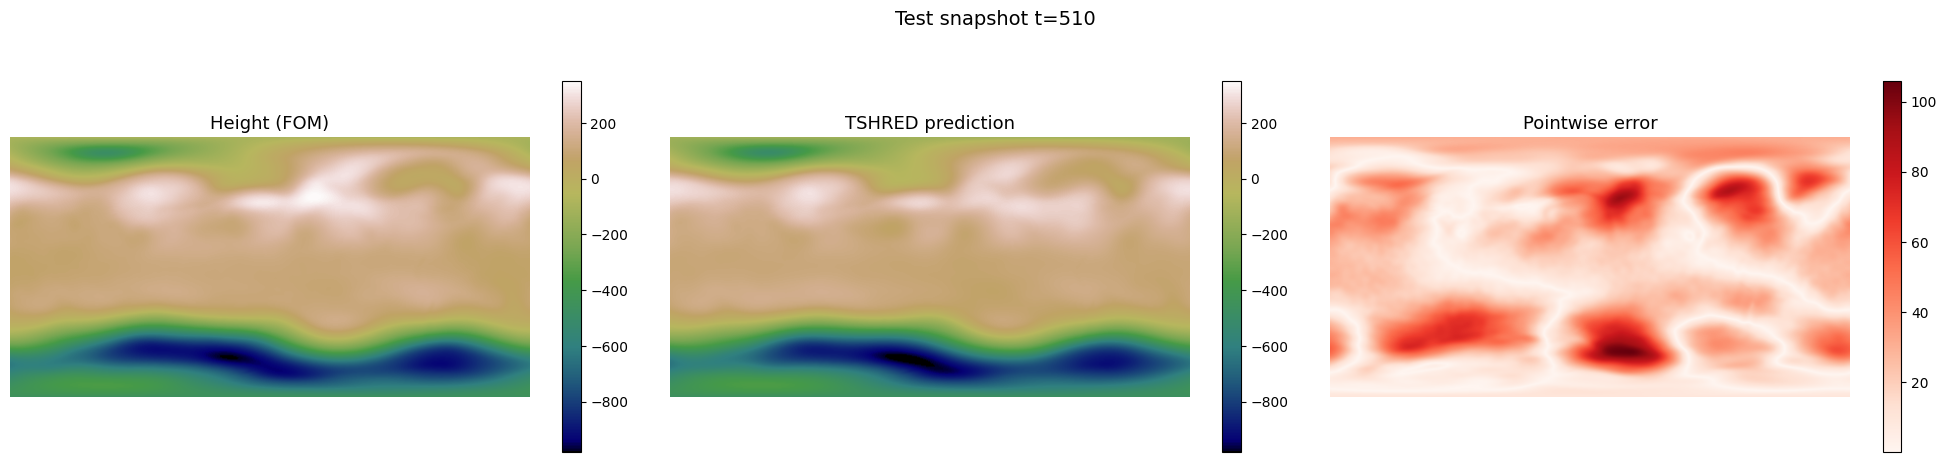

In [53]:
# FOM vs TSHRED RECONSTRUCTION - static snapshot comparison (same format as SHRED-ROM)

# Rebuild full H_hat over all time indices  
H_hat = torch.zeros(ntimes, nheight)
H_hat[idx_train] = H_hat_train
H_hat[idx_valid] = H_hat_valid
H_hat[idx_test]  = H_hat_test

t = idx_test[len(idx_test)//2]   # pick a representative test snapshot

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
titles = ("Height (FOM)", "TSHRED prediction", "Pointwise error")
fields = [H[t], H_hat[t], (H[t] - H_hat[t]).abs()]
cmaps  = ["gist_earth", "gist_earth", "Reds"]

vmin, vmax = H[t].min().item(), H[t].max().item()

for ax, field, title, cmap in zip(axes, fields, titles, cmaps):
    plt.sca(ax)
    im = ax.imshow(field.reshape(Lx, Ly), cmap=cmap,
                   vmin=(vmin if cmap != "Reds" else None),
                   vmax=(vmax if cmap != "Reds" else None),
                   origin='lower')
    plt.colorbar(im, ax=ax, shrink=0.85)
    ax.set_title(title, fontsize=13)
    ax.axis('off')

plt.suptitle(f"Test snapshot t={t}", fontsize=14)
plt.tight_layout()
plt.show()

## Broken sensors

In [54]:
# BROKEN SENSORS SIMULATION
# short broken : random Bernoulli drops
# long broken  : contiguous outage interval

short_broken = 1   # number of sensors with random drops
long_broken  = 1   # number of sensors with a contiguous outage

# Assign which sensors are broken (first short_broken sensors → random drops,
# next long_broken sensors → long outage)
idx_short_broken_s = np.arange(0, short_broken)
idx_long_broken_s  = np.arange(short_broken, short_broken + long_broken)

# Work on a float copy so NaN can be written
sensors_data = sensors_data.float()

# SHORT BROKEN: Bernoulli mask with probability p_short_broken
p_short_broken = 0.2
for local_idx in idx_short_broken_s:
    broken_mask = torch.rand(sensors_data[:, local_idx].shape) < p_short_broken
    print(f"Short broken sensor {local_idx} (coord {sensors_coordinates[local_idx]}): "
          f"{broken_mask.sum().item()} of {ntimes} steps masked")
    sensors_data[:, local_idx][broken_mask] = float('nan')

# LONG BROKEN: contiguous interval
for local_idx in idx_long_broken_s:
    t1, t2 = np.random.randint(0, ntimes, size=2)
    t_start, t_end = min(t1, t2), max(t1, t2)
    if t_end - t_start < 30:                          # ensure a minimum outage length
        t_end = min(t_start + 38, ntimes - 1)
    print(f"Long broken sensor  {local_idx} (coord {sensors_coordinates[local_idx]}): "
          f"steps {t_start} to {t_end} masked")
    sensors_data[t_start:t_end + 1, local_idx] = float('nan')

Short broken sensor 0 (coord [144 465]): 184 of 1008 steps masked
Long broken sensor  1 (coord [217 217]): steps 660 to 692 masked


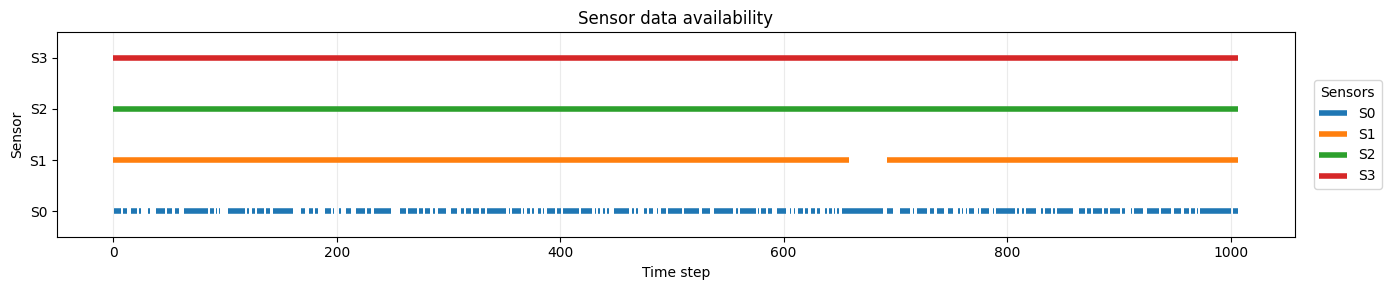

In [55]:
# PLOT DATA AVAILABILITY

def plot_data_availability(sensor_data, title_prefix, sensor_labels=None):
    """sensor_data: (ntimes, nsensors)"""
    availability = (~torch.isnan(sensor_data)).to(torch.float32).cpu().numpy()
    time          = np.arange(availability.shape[0])
    nsensors_plot = availability.shape[1]

    if sensor_labels is None:
        sensor_labels = np.arange(nsensors_plot)
    sensor_labels = np.asarray(sensor_labels)

    fig_height = max(3.0, 0.7 * nsensors_plot)
    _, ax = plt.subplots(1, 1, figsize=(14, fig_height))

    for sensor_idx in range(nsensors_plot):
        line = np.where(availability[:, sensor_idx] > 0.5, sensor_idx + 1.0, np.nan)
        ax.plot(time, line, linewidth=4, solid_capstyle="butt", label=f"S{sensor_labels[sensor_idx]}")

    ax.set_xlabel("Time step")
    ax.set_ylabel("Sensor")
    ax.set_yticks(np.arange(1, nsensors_plot + 1))
    ax.set_yticklabels([f"S{label}" for label in sensor_labels])
    ax.set_ylim(0.5, nsensors_plot + 0.5)
    ax.grid(True, axis="x", alpha=0.25)
    ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), title="Sensors")
    plt.title(title_prefix)
    plt.tight_layout()
    plt.show()

plot_data_availability(sensors_data, "Sensor data availability", sensor_labels=np.arange(nsensors))

In [56]:

# RE-SPLIT THE BROKEN sensors_data INTO SCALED input_train / input_val / input_test
# (sensors_data now contains NaN from the broken-sensor simulation above)

def scale_with_nan(data: torch.Tensor, scaler) -> torch.Tensor:
    """Apply a fitted MinMaxScaler to a tensor that may contain NaN.
    NaN positions are preserved after scaling."""
    nan_mask = torch.isnan(data)
    scaled = torch.from_numpy(scaler.transform(data.numpy())).float()
    scaled[nan_mask] = float('nan')
    return scaled

input_train = scale_with_nan(sensors_data[idx_train], scaler_sensors)  # (ntrain, nsensors)
input_val   = scale_with_nan(sensors_data[idx_valid], scaler_sensors)   # (nvalid, nsensors)
input_test  = scale_with_nan(sensors_data[idx_test],  scaler_sensors)   # (ntest,  nsensors)

print(f"input_train  shape: {input_train.shape}  |  NaN: {torch.isnan(input_train).sum().item()}")
print(f"input_val    shape: {input_val.shape}  |  NaN: {torch.isnan(input_val).sum().item()}")
print(f"input_test   shape: {input_test.shape}  |  NaN: {torch.isnan(input_test).sum().item()}")

# ---------------------------------------------------------------------------
# SHARED HELPER: build datasets, train TSHRED, evaluate, return error dict
# ---------------------------------------------------------------------------

def build_datasets(X_train, X_val, X_test, lag=100):
    """Wrap inputs with Padding and pair with POD targets."""
    train_in = Padding(X_train.unsqueeze(0), lag).to(device)
    val_in   = Padding(X_val.unsqueeze(0),   lag).to(device)
    test_in  = Padding(X_test.unsqueeze(0),  lag).to(device)

    train_out = Padding(H_POD_train.unsqueeze(0), 1).squeeze(1).to(device)
    val_out   = Padding(H_POD_valid.unsqueeze(0), 1).squeeze(1).to(device)
    test_out  = Padding(H_POD_test.unsqueeze(0),  1).squeeze(1).to(device)

    return (TimeSeriesDataset(train_in, train_out),
            TimeSeriesDataset(val_in,   val_out),
            TimeSeriesDataset(test_in,  test_out),
            train_in, val_in, test_in)

def build_masked_datasets(X_train, X_val, X_test, mask_train, mask_val, mask_test, lag=100):
    """Wrap inputs and boolean key masks with Padding; return MaskedTimeSeriesDataset triples.
    mask_*: (nsamples, nsensors) bool tensors — True = present.
    Key mask (per-timestep): True if ≥1 sensor is available at that step.
    """
    train_in = Padding(X_train.unsqueeze(0), lag).to(device)
    val_in   = Padding(X_val.unsqueeze(0),   lag).to(device)
    test_in  = Padding(X_test.unsqueeze(0),  lag).to(device)

    train_out = Padding(H_POD_train.unsqueeze(0), 1).squeeze(1).to(device)
    val_out   = Padding(H_POD_valid.unsqueeze(0), 1).squeeze(1).to(device)
    test_out  = Padding(H_POD_test.unsqueeze(0),  1).squeeze(1).to(device)

    # Per-timestep key mask: (nsamples,) → unsqueeze → (1, nsamples) → PaddingMask → (nsamples, lag)
    km_train = PaddingMask(mask_train.any(dim=-1).unsqueeze(0), lag).to(device)
    km_val   = PaddingMask(mask_val.any(dim=-1).unsqueeze(0),   lag).to(device)
    km_test  = PaddingMask(mask_test.any(dim=-1).unsqueeze(0),  lag).to(device)

    return (MaskedTimeSeriesDataset(train_in, km_train, train_out),
            MaskedTimeSeriesDataset(val_in,   km_val,   val_out),
            MaskedTimeSeriesDataset(test_in,  km_test,  test_out),
            train_in, val_in, test_in, km_train, km_val, km_test)

def create_GRUD_input(input_data: torch.Tensor) -> torch.Tensor:
    """Build the 4-channel GRU-D input tensor from a (nsamples, nsensors) input.
    Returns shape (1, 4, nsamples, nsensors).
    Channels: [X, X_last_obsv, Mask, Delta]
    """
    nsamples, n_s = input_data.shape
    out = torch.zeros(1, 4, nsamples, n_s)
    for sensor in range(n_s):
        series = input_data[:, sensor]
        # channel 0: raw values (NaN → 0)
        out[0, 0, :, sensor] = torch.nan_to_num(series, nan=0.0)
        for t in range(1, nsamples):
            if torch.isnan(series[t]):
                out[0, 1, t, sensor] = out[0, 1, t - 1, sensor]  # carry forward last observed
                out[0, 2, t, sensor] = 0.0                        # mask = missing
                out[0, 3, t, sensor] = out[0, 3, t - 1, sensor] + 1.0  # delta += 1
            else:
                out[0, 1, t, sensor] = series[t]   # last observed = current value
                out[0, 2, t, sensor] = 1.0          # mask = observed
                out[0, 3, t, sensor] = 0.0          # delta reset
    return out

def build_grud_datasets(X_train, X_val, X_test, lag=100):
    """Build 4-channel GRU-D datasets from (nsamples, nsensors) inputs.
    Returns datasets, padded inputs, and the raw grud_train tensor (for X_mean).
    """
    grud_train = create_GRUD_input(X_train)   # (1, 4, ntrain, nsensors)
    grud_val   = create_GRUD_input(X_val)
    grud_test  = create_GRUD_input(X_test)

    train_in = PaddingGRUD(grud_train, lag).to(device)   # (ntrain, 4, lag, nsensors)
    val_in   = PaddingGRUD(grud_val,   lag).to(device)
    test_in  = PaddingGRUD(grud_test,  lag).to(device)

    train_out = Padding(H_POD_train.unsqueeze(0), 1).squeeze(1).to(device)
    val_out   = Padding(H_POD_valid.unsqueeze(0), 1).squeeze(1).to(device)
    test_out  = Padding(H_POD_test.unsqueeze(0),  1).squeeze(1).to(device)

    return (TimeSeriesDataset(train_in, train_out),
            TimeSeriesDataset(val_in,   val_out),
            TimeSeriesDataset(test_in,  test_out),
            train_in, val_in, test_in, grud_train)

def evaluate_tshred(model, train_in, val_in, test_in, train_errors, valid_errors, model_name,
                   train_mask=None, val_mask=None, test_mask=None):
    """Inverse-project POD predictions → full field and compute MRE.
    Pass *_mask to forward() for Idea 2.B (explicit key-padding mask)."""
    VH_local = torch.from_numpy(VH_POD).float()    # (POD_modes, nheight)
    model.freeze()

    def reconstruct(X_in, km=None):
        pred = model(X_in, mask=km).cpu()
        return torch.from_numpy(
            scalerH_POD.inverse_transform(pred.detach().numpy())
        ).float() @ VH_local

    H_hat_tr = reconstruct(train_in, train_mask)
    H_hat_va = reconstruct(val_in,   val_mask)
    H_hat_te = reconstruct(test_in,  test_mask)

    entry = {
        "model":     model_name,
        "train_mre": num2p(mre(H[idx_train], H_hat_tr)),
        "valid_mre": num2p(mre(H[idx_valid], H_hat_va)),
        "test_mre":  num2p(mre(H[idx_test],  H_hat_te)),
    }
    ERRORS.append(entry)
    print(pd.DataFrame(ERRORS).to_string())
    return H_hat_tr, H_hat_va, H_hat_te

def evaluate_grud(model, train_in, val_in, test_in, train_errors, valid_errors, model_name):
    """Inverse-project GRU-D POD predictions → full field and compute MRE."""
    VH_local = torch.from_numpy(VH_POD).float()
    model.freeze()

    def reconstruct(X_in):
        pred = model(X_in).cpu()
        return torch.from_numpy(
            scalerH_POD.inverse_transform(pred.detach().numpy())
        ).float() @ VH_local

    H_hat_tr = reconstruct(train_in)
    H_hat_va = reconstruct(val_in)
    H_hat_te = reconstruct(test_in)

    entry = {
        "model":     model_name,
        "train_mre": num2p(mre(H[idx_train], H_hat_tr)),
        "valid_mre": num2p(mre(H[idx_valid], H_hat_va)),
        "test_mre":  num2p(mre(H[idx_test],  H_hat_te)),
    }
    ERRORS.append(entry)
    print(pd.DataFrame(ERRORS).to_string())
    return H_hat_tr, H_hat_va, H_hat_te

def plot_training_curves(train_errors, valid_errors, title):
    plt.figure(figsize=(10, 5))
    plt.plot(train_errors, label='Train MRE')
    plt.plot(valid_errors, label='Validation MRE')
    plt.xlabel('Epoch')
    plt.ylabel('MRE Loss')
    plt.title(title)
    plt.legend()
    plt.grid()
    plt.show()

def make_model_args(d_model, lag=100):
    return dict(
        encoder         = "vanilla_transformer",
        encoder_depth   = 1,
        d_model         = d_model,
        n_heads         = 4,
        dim_feedforward = 64,
        hidden_size     = 32,
        input_length    = lag,
        decoder         = "cnn",
        decoder_depth   = 2,
        output_size     = POD_modes,
        dropout         = 0.0,
        device          = device,
    )


input_train  shape: torch.Size([806, 4])  |  NaN: 172
input_val    shape: torch.Size([101, 4])  |  NaN: 20
input_test   shape: torch.Size([101, 4])  |  NaN: 25


## Idea 0: Only Available Sensors

Kept sensors:		 [2 3]
Removed sensors:	 [0 1]
Available sensors:	 2


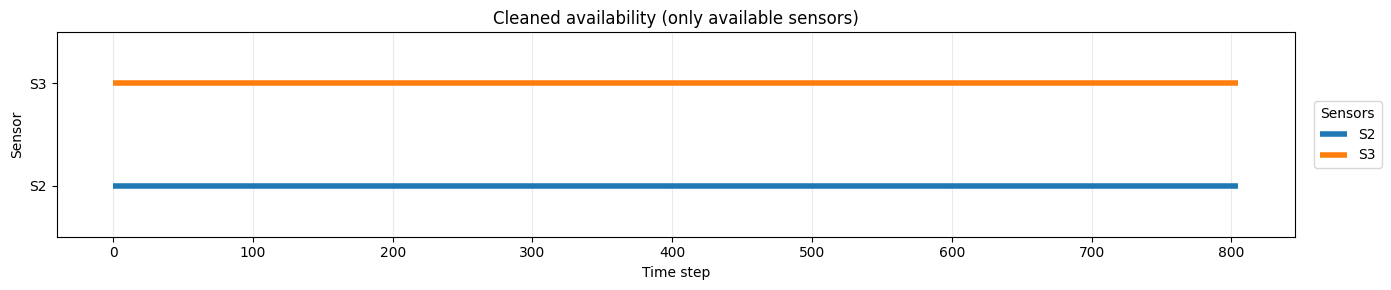


Train:  torch.Size([806, 100, 2]) → torch.Size([75])
Val:    torch.Size([101, 100, 2])
Test:   torch.Size([101, 100, 2])


Training:  61%|██████    | 612/1000 [01:21<00:51,  7.48it/s, Train Error=25.525%, Val Error=31.785%, Patience=299, Best Val Error=31.092%, LR=6.25e-05]

Early stopping at epoch 613


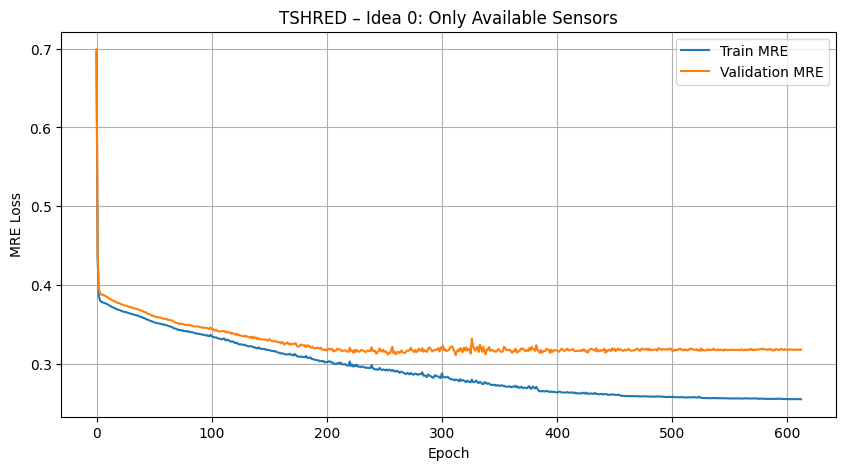

                            model train_mre valid_mre test_mre
0                          TSHRED    3.879%    4.525%   4.662%
1  Idea 0: Only Available Sensors    8.728%   11.240%  11.805%


In [57]:
# IDEA 0: ONLY AVAILABLE SENSORS
# Keep only sensors that are never NaN in any split.

always_available_mask = (
    ~torch.isnan(input_train).any(dim=0) &
    ~torch.isnan(input_val).any(dim=0)   &
    ~torch.isnan(input_test).any(dim=0)
)
keep_sensor_idx    = np.where(always_available_mask.cpu().numpy())[0]
removed_sensor_idx = np.setdiff1d(np.arange(nsensors), keep_sensor_idx)
navailable_sensors = len(keep_sensor_idx)

print("Kept sensors:\t\t", keep_sensor_idx)
print("Removed sensors:\t", removed_sensor_idx)
print("Available sensors:\t", navailable_sensors)

# Plot cleaned availability
plot_data_availability(
    input_train[:, keep_sensor_idx],
    "Cleaned availability (only available sensors)",
    sensor_labels=keep_sensor_idx,
)

# Build datasets
cleaned_train = input_train[:, keep_sensor_idx]
cleaned_val   = input_val[:,   keep_sensor_idx]
cleaned_test  = input_test[:,  keep_sensor_idx]

train_ds_0, val_ds_0, test_ds_0, train_in_0, val_in_0, test_in_0 = \
    build_datasets(cleaned_train, cleaned_val, cleaned_test)

print(f"\nTrain:  {train_in_0.shape} → {train_ds_0[0][1].shape}")
print(f"Val:    {val_in_0.shape}")
print(f"Test:   {test_in_0.shape}")

# Train
tshred_0 = TSHRED(args=make_model_args(navailable_sensors))
train_errors_0, valid_errors_0 = fit(
    tshred_0, train_ds_0, val_ds_0,
    batch_size=64, epochs=1000, lr=1e-3, verbose=True, patience=300, scheduler_patience=70,
)
plot_training_curves(train_errors_0, valid_errors_0, "TSHRED – Idea 0: Only Available Sensors")

# Evaluate
H_hat_tr_0, H_hat_va_0, H_hat_te_0 = evaluate_tshred(
    tshred_0, train_in_0, val_in_0, test_in_0,
    train_errors_0, valid_errors_0, "Idea 0: Only Available Sensors",
)


## Idea 1.A: Median Imputer

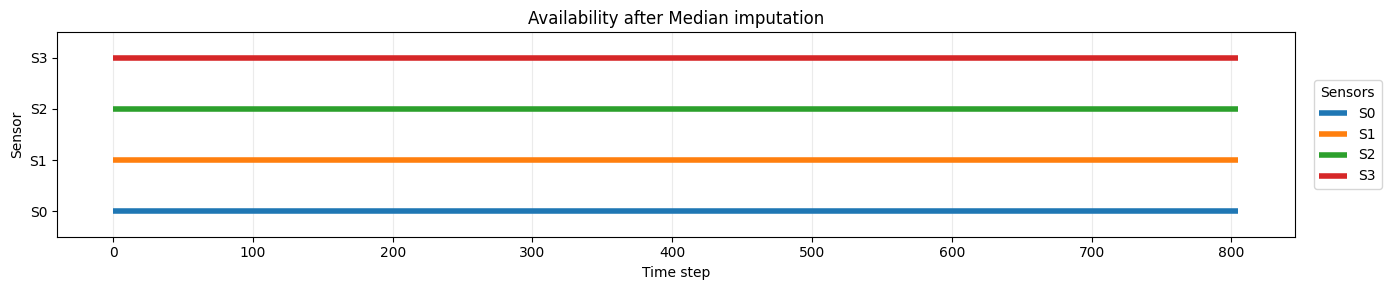

Training:  86%|████████▋ | 863/1000 [01:54<00:18,  7.57it/s, Train Error=20.730%, Val Error=23.965%, Patience=299, Best Val Error=23.715%, LR=6.25e-05]


Early stopping at epoch 864


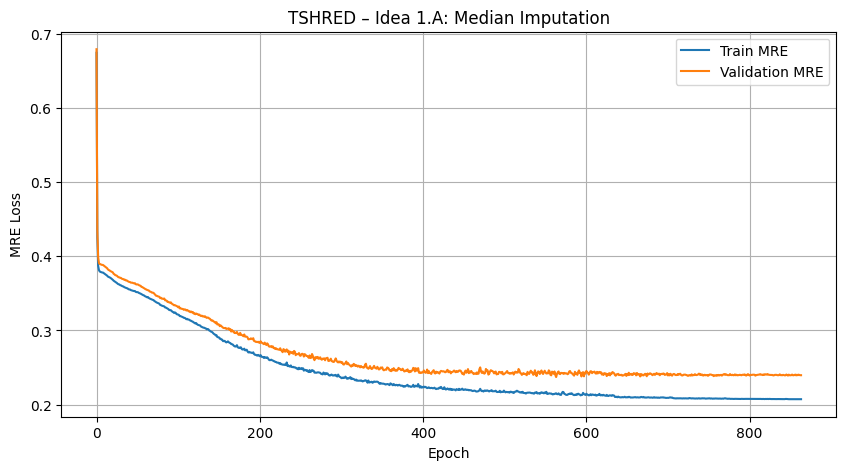

                            model train_mre valid_mre test_mre
0                          TSHRED    3.879%    4.525%   4.662%
1  Idea 0: Only Available Sensors    8.728%   11.240%  11.805%
2     Idea 1.A: Median Imputation    4.254%    5.995%   6.170%


In [58]:
# DEFINE MEDIAN IMPUTER
# Computes per-sensor median over the training set (NaN-aware) and fills missing values.

def get_train_medians(X_train: torch.Tensor) -> torch.Tensor:
    """X_train: (ntrain, nsensors)  →  medians: (nsensors,)"""
    medians = torch.nanmedian(X_train, dim=0).values
    return torch.nan_to_num(medians, nan=0.0)   # fallback 0 if sensor fully NaN

def apply_median_imputation(X: torch.Tensor, medians: torch.Tensor) -> torch.Tensor:
    """Replace NaN entries in X with the corresponding sensor median."""
    X_imp = X.clone()
    nan_mask = torch.isnan(X_imp)
    sensor_idx = nan_mask.nonzero(as_tuple=True)[1]
    X_imp[nan_mask] = medians[sensor_idx]
    return X_imp

# APPLY AND SHOW AVAILABILITY
medians = get_train_medians(input_train)

imp_train_1a = apply_median_imputation(input_train, medians)
imp_val_1a   = apply_median_imputation(input_val,   medians)
imp_test_1a  = apply_median_imputation(input_test,  medians)

plot_data_availability(imp_train_1a, "Availability after Median imputation", sensor_labels=np.arange(nsensors))

# BUILD DATASETS + TRAIN
train_ds_1a, val_ds_1a, test_ds_1a, train_in_1a, val_in_1a, test_in_1a = \
    build_datasets(imp_train_1a, imp_val_1a, imp_test_1a)

tshred_1a = TSHRED(args=make_model_args(nsensors))
train_errors_1a, valid_errors_1a = fit(
    tshred_1a, train_ds_1a, val_ds_1a,
    batch_size=64, epochs=1000, lr=1e-3, verbose=True, patience=300, scheduler_patience=70,
)
plot_training_curves(train_errors_1a, valid_errors_1a, "TSHRED – Idea 1.A: Median Imputation")

# EVALUATE
H_hat_tr_1a, H_hat_va_1a, H_hat_te_1a = evaluate_tshred(
    tshred_1a, train_in_1a, val_in_1a, test_in_1a,
    train_errors_1a, valid_errors_1a, "Idea 1.A: Median Imputation",
)


## Idea 1.B: Last-Value Imputer

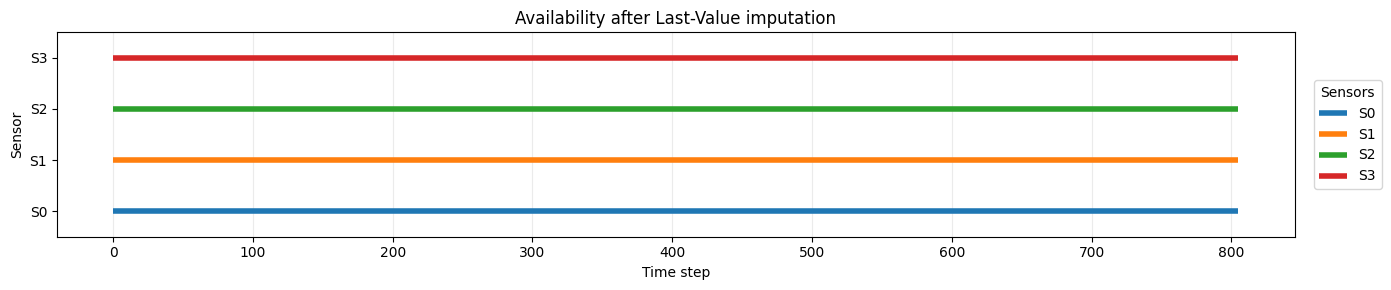

Training: 100%|██████████| 1000/1000 [02:16<00:00,  7.30it/s, Train Error=19.980%, Val Error=22.699%, Patience=227, Best Val Error=22.652%, LR=6.25e-05]

Training Complete (1000 epochs)


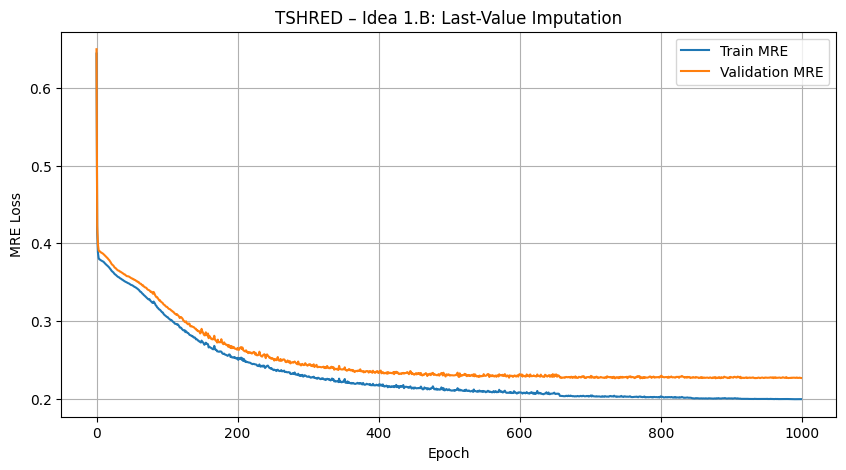

                             model train_mre valid_mre test_mre
0                           TSHRED    3.879%    4.525%   4.662%
1   Idea 0: Only Available Sensors    8.728%   11.240%  11.805%
2      Idea 1.A: Median Imputation    4.254%    5.995%   6.170%
3  Idea 1.B: Last-Value Imputation    4.437%    5.670%   5.724%


In [59]:
# DEFINE LAST-VALUE IMPUTER
# For each sensor, replace NaN with the most recent valid reading.
# If the first value is NaN, fall back to 0.

def apply_LV_imputation(X: torch.Tensor) -> torch.Tensor:
    """X: (ntimes, nsensors)"""
    X_imp = X.clone()
    for j in range(X_imp.shape[1]):        # loop over sensors
        ts = X_imp[:, j]
        nan_idx = torch.where(torch.isnan(ts))[0]
        if len(nan_idx) == 0:
            continue
        for idx in nan_idx:
            ts[idx] = 0.0 if idx == 0 else ts[idx - 1]
    return X_imp

# APPLY AND SHOW AVAILABILITY
imp_train_1b = apply_LV_imputation(input_train)
imp_val_1b   = apply_LV_imputation(input_val)
imp_test_1b  = apply_LV_imputation(input_test)

plot_data_availability(imp_train_1b, "Availability after Last-Value imputation", sensor_labels=np.arange(nsensors))

# BUILD DATASETS + TRAIN
train_ds_1b, val_ds_1b, test_ds_1b, train_in_1b, val_in_1b, test_in_1b = \
    build_datasets(imp_train_1b, imp_val_1b, imp_test_1b)

tshred_1b = TSHRED(args=make_model_args(nsensors))
train_errors_1b, valid_errors_1b = fit(
    tshred_1b, train_ds_1b, val_ds_1b,
    batch_size=64, epochs=1000, lr=1e-3, verbose=True, patience=300, scheduler_patience=70,
)
plot_training_curves(train_errors_1b, valid_errors_1b, "TSHRED – Idea 1.B: Last-Value Imputation")

# EVALUATE
H_hat_tr_1b, H_hat_va_1b, H_hat_te_1b = evaluate_tshred(
    tshred_1b, train_in_1b, val_in_1b, test_in_1b,
    train_errors_1b, valid_errors_1b, "Idea 1.B: Last-Value Imputation",
)


## Idea 2.A: Masked MHSA (zero-fill + availability flags)

Replace each NaN with 0 and append a binary availability flag channel, so the
model always knows which readings are real:

masked_input = cat([zero_filled_values,  availability_flags], dim=-1)   # (ntimes, 2·nsensors)

Input feature dim doubles: nsensors → 2·nsensors.

Missing in train: 172 / 3224
Augmented input shape: torch.Size([806, 8])  (was torch.Size([806, 4]))
Train: torch.Size([806, 100, 8]) → torch.Size([75])


Training:  92%|█████████▏| 1378/1500 [04:02<00:21,  5.68it/s, Train Error=20.222%, Val Error=23.836%, Patience=299, Best Val Error=23.696%, LR=3.13e-05]

Early stopping at epoch 1379


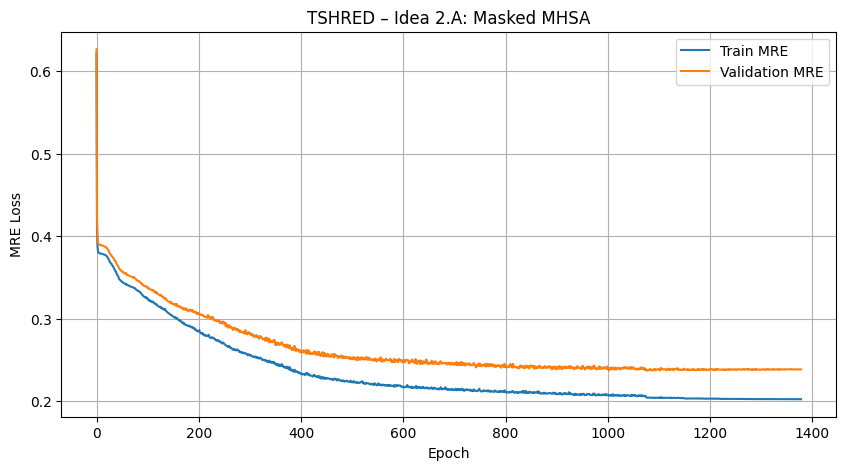

                             model train_mre valid_mre test_mre
0                           TSHRED    3.879%    4.525%   4.662%
1   Idea 0: Only Available Sensors    8.728%   11.240%  11.805%
2      Idea 1.A: Median Imputation    4.254%    5.995%   6.170%
3  Idea 1.B: Last-Value Imputation    4.437%    5.670%   5.724%
4            Idea 2.A: Masked MHSA    3.882%    5.396%   5.543%
5            Idea 2.A: Masked MHSA    3.760%    5.156%   5.932%


In [62]:
# IDEA 2.A: MASKED MHSA
# Availability masks: True = present, False = NaN
mask_train_2a = ~torch.isnan(input_train)   # (ntrain, nsensors)
mask_val_2a   = ~torch.isnan(input_val)
mask_test_2a  = ~torch.isnan(input_test)

print(f"Missing in train: {(~mask_train_2a).sum().item()} / {mask_train_2a.numel()}")

# Zero-fill and augment with availability flags → (ntimes, 2·nsensors)
masked_train_2a = torch.cat([input_train.nan_to_num(0.0), mask_train_2a.float()], dim=-1)
masked_val_2a   = torch.cat([input_val.nan_to_num(0.0),   mask_val_2a.float()],   dim=-1)
masked_test_2a  = torch.cat([input_test.nan_to_num(0.0),  mask_test_2a.float()],  dim=-1)

print(f"Augmented input shape: {masked_train_2a.shape}  (was {input_train.shape})")

# BUILD DATASETS + TRAIN  (d_model = 2·nsensors)
train_ds_2a, val_ds_2a, test_ds_2a, train_in_2a, val_in_2a, test_in_2a = \
    build_datasets(masked_train_2a, masked_val_2a, masked_test_2a)

print(f"Train: {train_in_2a.shape} → {train_ds_2a[0][1].shape}")

tshred_2a = TSHRED(args=make_model_args(2 * nsensors))
train_errors_2a, valid_errors_2a = fit(
    tshred_2a, train_ds_2a, val_ds_2a,
    batch_size=64, epochs=1500, lr=1e-3, verbose=True, patience=300, scheduler_patience=70,
)
plot_training_curves(train_errors_2a, valid_errors_2a, "TSHRED – Idea 2.A: Masked MHSA")

# EVALUATE
H_hat_tr_2a, H_hat_va_2a, H_hat_te_2a = evaluate_tshred(
    tshred_2a, train_in_2a, val_in_2a, test_in_2a,
    train_errors_2a, valid_errors_2a, "Idea 2.A: Masked MHSA",
)


## Idea 2.B: Double Masked MHSA (zero-fill + implicit flags + explicit key mask)

Two masking signals are passed to the model:

**Implicit mask** — availability flags appended to input features (nsensors → 2·nsensors):

masked_input = cat([zero_filled_values, availability_flags], dim=-1)

**Explicit key mask** — per-timestep boolean mask fed to the MHSA layers to block attention on fully-missing steps:

key_mask = mask.any(dim=-1)   # (nsamples,) — True if ≥1 sensor available at that step

Missing in train: 172 / 3224
Augmented input:  torch.Size([806, 8])  (was torch.Size([806, 4]))
Train:  torch.Size([806, 100, 8]) + key_mask torch.Size([806, 100]) → torch.Size([75])
Val:    torch.Size([101, 100, 8])
Test:   torch.Size([101, 100, 8])


Training:  66%|██████▋   | 996/1500 [03:03<01:32,  5.44it/s, Train Error=20.030%, Val Error=25.200%, Patience=299, Best Val Error=24.972%, LR=3.13e-05]


Early stopping at epoch 997


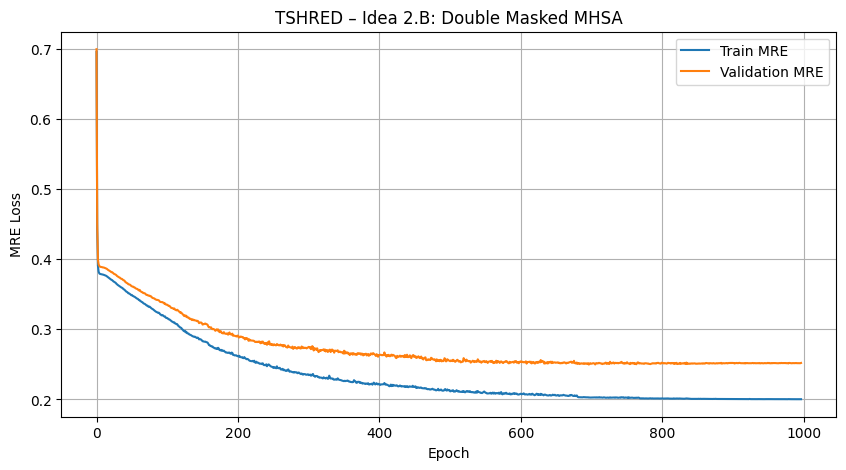

                             model train_mre valid_mre test_mre
0                           TSHRED    3.879%    4.525%   4.662%
1   Idea 0: Only Available Sensors    8.728%   11.240%  11.805%
2      Idea 1.A: Median Imputation    4.254%    5.995%   6.170%
3  Idea 1.B: Last-Value Imputation    4.437%    5.670%   5.724%
4            Idea 2.A: Masked MHSA    3.882%    5.396%   5.543%
5            Idea 2.A: Masked MHSA    3.760%    5.156%   5.932%
6     Idea 2.B: Double Masked MHSA    3.493%    5.771%   5.963%
7     Idea 2.B: Double Masked MHSA    3.764%    6.057%   6.429%


In [65]:
# IDEA 2.B: DOUBLE MASKED MHSA
# Availability masks
mask_train_2b = ~torch.isnan(input_train)   # (ntrain, nsensors)
mask_val_2b   = ~torch.isnan(input_val)
mask_test_2b  = ~torch.isnan(input_test)

print(f"Missing in train: {(~mask_train_2b).sum().item()} / {mask_train_2b.numel()}")

# Zero-fill + append availability flags → (nsamples, 2·nsensors)
masked_train_2b = torch.cat([input_train.nan_to_num(0.0), mask_train_2b.float()], dim=-1)
masked_val_2b   = torch.cat([input_val.nan_to_num(0.0),   mask_val_2b.float()],   dim=-1)
masked_test_2b  = torch.cat([input_test.nan_to_num(0.0),  mask_test_2b.float()],  dim=-1)

print(f"Augmented input:  {masked_train_2b.shape}  (was {input_train.shape})")

# BUILD MaskedTimeSeriesDataset with per-timestep key masks
(train_ds_2b, val_ds_2b, test_ds_2b,
 train_in_2b, val_in_2b, test_in_2b,
 km_train_2b, km_val_2b, km_test_2b) = build_masked_datasets(
    masked_train_2b, masked_val_2b, masked_test_2b,
    mask_train_2b,   mask_val_2b,   mask_test_2b,
)

print(f"Train:  {train_in_2b.shape} + key_mask {km_train_2b.shape} → {train_ds_2b[0][2].shape}")
print(f"Val:    {val_in_2b.shape}")
print(f"Test:   {test_in_2b.shape}")

# TRAIN  (d_model = 2·nsensors, fit handles MaskedTimeSeriesDataset automatically)
tshred_2b = TSHRED(args=make_model_args(2 * nsensors))
train_errors_2b, valid_errors_2b = fit(
    tshred_2b, train_ds_2b, val_ds_2b,
    batch_size=64, epochs=1500, lr=1e-3, verbose=True, patience=300, scheduler_patience=70,
)
plot_training_curves(train_errors_2b, valid_errors_2b, "TSHRED – Idea 2.B: Double Masked MHSA")

# EVALUATE (pass explicit key masks to forward())
H_hat_tr_2b, H_hat_va_2b, H_hat_te_2b = evaluate_tshred(
    tshred_2b, train_in_2b, val_in_2b, test_in_2b,
    train_errors_2b, valid_errors_2b, "Idea 2.B: Double Masked MHSA",
    train_mask=km_train_2b, val_mask=km_val_2b, test_mask=km_test_2b,
)


## Idea 3.A: GRU-D

Decay-aware recurrent encoder that natively handles missing values.
The 4-channel input tensor encodes:

* **X** – raw values (NaN → 0)
* **X_last_obsv** – last observed value carried forward
* **Mask** – 1 if observed, 0 if missing
* **Delta** – time elapsed since last observation (incremented per missing step)

The GRU-D cell uses these channels to apply input decay and hidden-state decay, weighting observations by recency.


Train:  torch.Size([806, 4, 100, 4]) → torch.Size([75])
Val:    torch.Size([101, 4, 100, 4])
Test:   torch.Size([101, 4, 100, 4])
X_mean shape: torch.Size([1, 806, 4])


Training: 100%|██████████| 300/300 [05:24<00:00,  1.08s/it, Train Error=14.542%, Val Error=20.814%, Patience=14, Best Val Error=20.719%, LR=1.00e-03]

Training Complete (300 epochs)


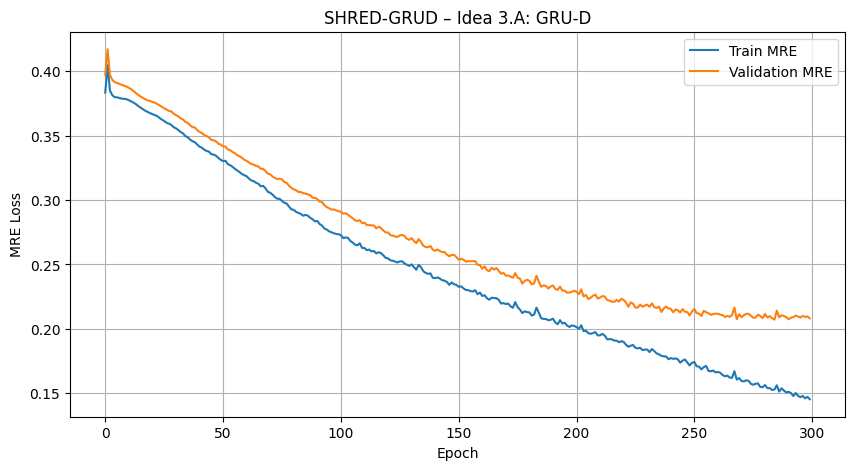

                             model train_mre valid_mre test_mre
0                           TSHRED    3.879%    4.525%   4.662%
1   Idea 0: Only Available Sensors    8.728%   11.240%  11.805%
2      Idea 1.A: Median Imputation    4.254%    5.995%   6.170%
3  Idea 1.B: Last-Value Imputation    4.437%    5.670%   5.724%
4            Idea 2.A: Masked MHSA    3.882%    5.396%   5.543%
5            Idea 2.A: Masked MHSA    3.760%    5.156%   5.932%
6     Idea 2.B: Double Masked MHSA    3.493%    5.771%   5.963%
7     Idea 2.B: Double Masked MHSA    3.764%    6.057%   6.429%
8                  Idea 3.A: GRU-D    4.736%    6.138%   6.626%
9                  Idea 3.A: GRU-D    3.801%    6.018%   6.469%


In [68]:

# IDEA 3.A: GRU-D
# Build 4-channel GRU-D datasets from the broken sensor inputs
train_ds_3a, val_ds_3a, test_ds_3a, train_in_3a, val_in_3a, test_in_3a, grud_train_3a = \
    build_grud_datasets(input_train, input_val, input_test)

print(f"Train:  {train_in_3a.shape} → {train_ds_3a[0][1].shape}")
print(f"Val:    {val_in_3a.shape}")
print(f"Test:   {test_in_3a.shape}")

# X_mean: mean of the X channel (ch 0) used for decay initialisation in GRU-D
# shape: (1, ntrain, nsensors)
X_mean_3a = grud_train_3a[:, 0, :, :].mean(dim=0, keepdim=True).to(device)
print(f"X_mean shape: {X_mean_3a.shape}")

# Train
shred_grud_3a = SHRED_GRUD(
    nsensors, POD_modes, X_mean_3a,
    hidden_size=64, decoder_sizes=[350, 400], dropout=0.1
)
train_errors_3a, valid_errors_3a = fit_grud(
    shred_grud_3a, train_ds_3a, val_ds_3a,
    batch_size=64, epochs=300, lr=1e-3, verbose=True, patience=100, scheduler_patience=30,
)
plot_training_curves(train_errors_3a, valid_errors_3a, "SHRED-GRUD – Idea 3.A: GRU-D")

# Evaluate
H_hat_tr_3a, H_hat_va_3a, H_hat_te_3a = evaluate_grud(
    shred_grud_3a, train_in_3a, val_in_3a, test_in_3a,
    train_errors_3a, valid_errors_3a, "Idea 3.A: GRU-D",
)


## Idea 3.B: Attention GRU-D

Same 4-channel GRU-D encoder as Idea 3.A but with a self-attention layer applied to the hidden states across the lag window before decoding.
This allows the model to selectively weight time steps regardless of their recency.


Training: 100%|██████████| 400/400 [09:02<00:00,  1.36s/it, Train Error=12.174%, Val Error=22.344%, Patience=77, Best Val Error=21.736%, LR=2.50e-04]

Training Complete (400 epochs)


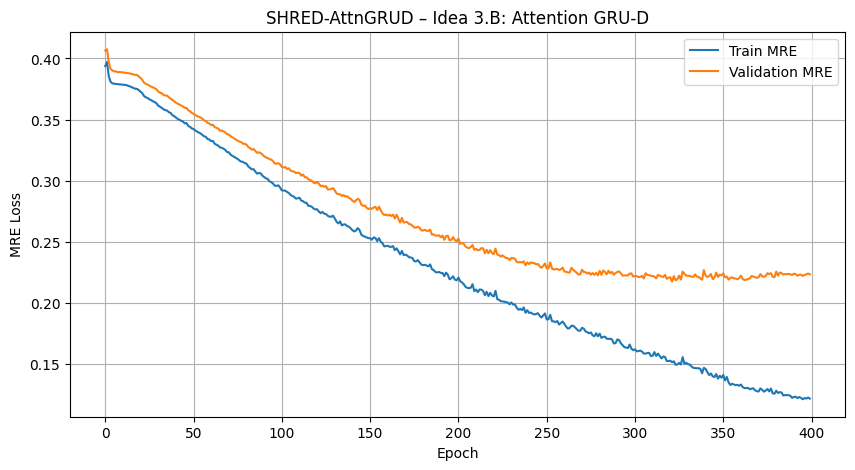

                              model train_mre valid_mre test_mre
0                            TSHRED    3.879%    4.525%   4.662%
1    Idea 0: Only Available Sensors    8.728%   11.240%  11.805%
2       Idea 1.A: Median Imputation    4.254%    5.995%   6.170%
3   Idea 1.B: Last-Value Imputation    4.437%    5.670%   5.724%
4             Idea 2.A: Masked MHSA    3.882%    5.396%   5.543%
5             Idea 2.A: Masked MHSA    3.760%    5.156%   5.932%
6      Idea 2.B: Double Masked MHSA    3.493%    5.771%   5.963%
7      Idea 2.B: Double Masked MHSA    3.764%    6.057%   6.429%
8                   Idea 3.A: GRU-D    4.736%    6.138%   6.626%
9                   Idea 3.A: GRU-D    3.801%    6.018%   6.469%
10        Idea 3.B: Attention GRU-D    4.865%    6.656%   6.956%
11        Idea 3.B: Attention GRU-D    3.149%    6.756%   7.312%


In [70]:

# IDEA 3.B: ATTENTION GRU-D
# Re-use the same 4-channel GRUD datasets built for Idea 3.A
train_ds_3b, val_ds_3b, test_ds_3b, train_in_3b, val_in_3b, test_in_3b, grud_train_3b = \
    build_grud_datasets(input_train, input_val, input_test)

X_mean_3b = grud_train_3b[:, 0, :, :].mean(dim=0, keepdim=True).to(device)

# Initialize SHRED-AttnGRUD (same as SHRED-GRUD but with attention=True)
shred_attn_grud_3b = SHRED_GRUD(
    nsensors, POD_modes, X_mean_3b,
    hidden_size=64, decoder_sizes=[350, 400], dropout=0.1,
    attention=True,
)
train_errors_3b, valid_errors_3b = fit_grud(
    shred_attn_grud_3b, train_ds_3b, val_ds_3b,
    batch_size=64, epochs=400, lr=1e-3, verbose=True, patience=100, scheduler_patience=30,
)
plot_training_curves(train_errors_3b, valid_errors_3b, "SHRED-AttnGRUD – Idea 3.B: Attention GRU-D")

# Evaluate
H_hat_tr_3b, H_hat_va_3b, H_hat_te_3b = evaluate_grud(
    shred_attn_grud_3b, train_in_3b, val_in_3b, test_in_3b,
    train_errors_3b, valid_errors_3b, "Idea 3.B: Attention GRU-D",
)


## Results

using PODmodes = 75, scheduler_patience = 70, less train (varying +-50)


In [71]:
# SUMMARY TABLE – all strategies

print(pd.DataFrame(ERRORS).to_string())

                              model train_mre valid_mre test_mre
0                            TSHRED    3.879%    4.525%   4.662%
1    Idea 0: Only Available Sensors    8.728%   11.240%  11.805%
2       Idea 1.A: Median Imputation    4.254%    5.995%   6.170%
3   Idea 1.B: Last-Value Imputation    4.437%    5.670%   5.724%
4             Idea 2.A: Masked MHSA    3.882%    5.396%   5.543%
5             Idea 2.A: Masked MHSA    3.760%    5.156%   5.932%
6      Idea 2.B: Double Masked MHSA    3.493%    5.771%   5.963%
7      Idea 2.B: Double Masked MHSA    3.764%    6.057%   6.429%
8                   Idea 3.A: GRU-D    4.736%    6.138%   6.626%
9                   Idea 3.A: GRU-D    3.801%    6.018%   6.469%
10        Idea 3.B: Attention GRU-D    4.865%    6.656%   6.956%
11        Idea 3.B: Attention GRU-D    3.149%    6.756%   7.312%


## Old Results

using PODmodes = 50, LR = 1e-3, scheduler_patience = 50 

In [ ]:
print(pd.DataFrame(ERRORS).to_string())

                             model train_mre valid_mre test_mre
0                           TSHRED    4.715%    7.280%   7.382%
1   Idea 0: Only Available Sensors   16.333%   21.936%  21.547%
2      Idea 1.A: Median Imputation    9.222%   13.403%  13.736%
3  Idea 1.B: Last-Value Imputation   14.030%   18.494%  17.865%
4            Idea 2.A: Masked MHSA    8.725%   12.581%  12.099%
5     Idea 2.B: Double Masked MHSA    9.446%   13.718%  14.039%
6                  Idea 3.A: GRU-D   15.802%   17.594%  16.858%
7        Idea 3.B: Attention GRU-D   15.291%   17.124%  16.444%
